Dataset Shape: (5000, 7)
Class Distribution:
Anomaly_Label
0    4750
1     250
Name: count, dtype: int64
Normal Training Windows: (2828, 10, 5)
Testing Windows: (991, 10, 5)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                          │ (None, 32)                  │           4,864 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ repeat_vector (RepeatVector)         │ (None, 10, 32)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_1 (LSTM)                        │ (None, 10, 32)              │           8,320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ time_distributed (TimeDistributed)   │ (None, 10, 5)               │             165 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 13,349 (52.14 KB)

 Trainable params: 13,349 (52.14 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
80/80 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - loss: 0.0574 - mae: 0.1862 - val_loss: 0.0264 - val_mae: 0.1275
Epoch 2/10
80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0240 - mae: 0.1218 - val_loss: 0.0214 - val_mae: 0.1144
Epoch 3/10
80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0215 - mae: 0.1148 - val_loss: 0.0206 - val_mae: 0.1123
Epoch 4/10
80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0210 - mae: 0.1134 - val_loss: 0.0202 - val_mae: 0.1111
Epoch 5/10
80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0205 - mae: 0.1119 - val_loss: 0.0197 - val_mae: 0.1096
Epoch 6/10
80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0200 - mae: 0.1103 - val_loss: 0.0192 - val_mae: 0.1080
Epoch 7/10
80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0196 - mae: 0.1087 - val_loss: 0.0188 - val_mae: 0.1062
Epoch 8/10
80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0192 - mae: 0.1071 - val_loss: 0.0185 - val_mae: 0.1053
Epoch 9/10
80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0189 - mae:

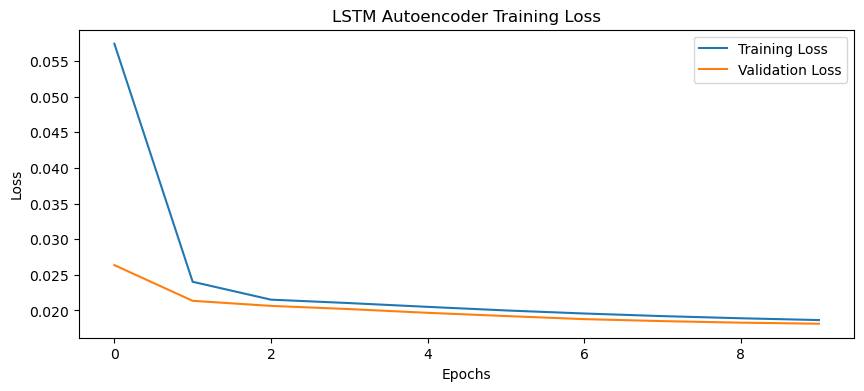

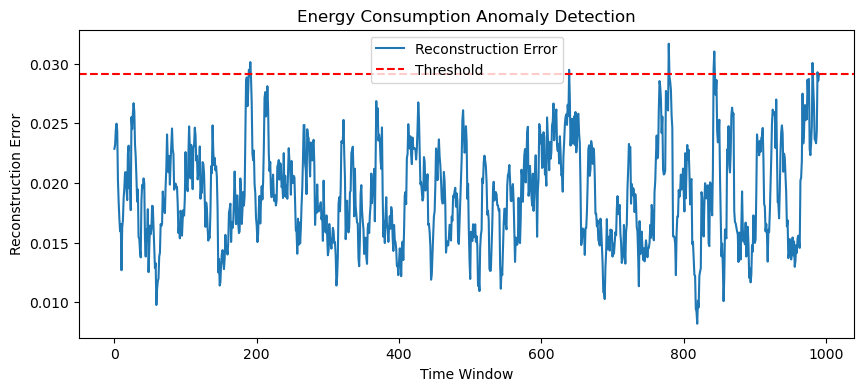

In [1]:
# Assignment 3C: Energy Anomaly Detection Using LSTM Autoencoder

# Step 1: Import Libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, RepeatVector, TimeDistributed, Dense
from tensorflow.keras.optimizers import Adam


# Step 2: Load Dataset

data = pd.read_csv("energy consumption.csv")

print("Dataset Shape:", data.shape)
print("Class Distribution:")
print(data["Anomaly_Label"].value_counts())


# Step 3: Preprocess Data

# Convert Timestamp to datetime
data["Timestamp"] = pd.to_datetime(
    data["Timestamp"],
    format="%d-%m-%Y %H:%M"
)

# Sort data by time
data = data.sort_values("Timestamp").reset_index(drop=True)

# Select input features
features = [
    "Electricity_Consumed",
    "Temperature",
    "Humidity",
    "Wind_Speed",
    "Avg_Past_Consumption"
]

# Fill missing values using training data statistics
split = int(len(data) * 0.8)

train_data = data.iloc[:split].copy()
test_data = data.iloc[split:].copy()

medians = train_data[features].median()

train_data[features] = train_data[features].fillna(medians)
test_data[features] = test_data[features].fillna(medians)

# Normalize features
scaler = MinMaxScaler()

normal_train = train_data[train_data["Anomaly_Label"] == 0]

scaler.fit(normal_train[features])

train_scaled = scaler.transform(train_data[features])
test_scaled = scaler.transform(test_data[features])


# Step 4: Create Time Windows

window_size = 10

def create_windows(values, labels, window_size):
    X = []
    y = []

    for i in range(len(values) - window_size + 1):
        X.append(values[i:i + window_size])

        # Window is anomalous if any reading is anomalous
        y.append(
            int(np.any(labels[i:i + window_size] == 1))
        )

    return np.array(X), np.array(y)


X_train, y_train = create_windows(
    train_scaled,
    train_data["Anomaly_Label"].values,
    window_size
)

X_test, y_test = create_windows(
    test_scaled,
    test_data["Anomaly_Label"].values,
    window_size
)

# Train only on normal windows
X_train_normal = X_train[y_train == 0]

print("Normal Training Windows:", X_train_normal.shape)
print("Testing Windows:", X_test.shape)


# Step 5: Define LSTM Autoencoder

model = Sequential([
    Input(shape=(window_size, len(features))),

    LSTM(32, activation="tanh"),

    RepeatVector(window_size),

    LSTM(32, activation="tanh", return_sequences=True),

    TimeDistributed(Dense(len(features)))
])


# Step 6: Compile Model

model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="mse",
    metrics=["mae"]
)

model.summary()


# Step 7: Train Model

history = model.fit(
    X_train_normal,
    X_train_normal,
    epochs=10,
    batch_size=32,
    validation_split=0.1,
    shuffle=True
)


# Step 8: Calculate Training Reconstruction Error

train_predictions = model.predict(
    X_train_normal,
    verbose=0
)

train_error = np.mean(
    np.square(X_train_normal - train_predictions),
    axis=(1, 2)
)


# Step 9: Set Threshold

threshold = np.percentile(train_error, 99)

print("Anomaly Threshold:", threshold)


# Step 10: Calculate Test Reconstruction Error

test_predictions = model.predict(X_test, verbose=0)

test_error = np.mean(
    np.square(X_test - test_predictions),
    axis=(1, 2)
)


# Step 11: Detect Anomalies

y_pred = (test_error > threshold).astype(int)


# Step 12: Evaluate Model

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, zero_division=0))
print("Recall:", recall_score(y_test, y_pred, zero_division=0))
print("F1 Score:", f1_score(y_test, y_pred, zero_division=0))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))


# Step 13: Plot Training Loss

plt.figure(figsize=(10, 4))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("LSTM Autoencoder Training Loss")
plt.legend()
plt.show()


# Step 14: Plot Reconstruction Errors

plt.figure(figsize=(10, 4))

plt.plot(test_error, label="Reconstruction Error")

plt.axhline(
    threshold,
    color="red",
    linestyle="--",
    label="Threshold"
)

plt.xlabel("Time Window")
plt.ylabel("Reconstruction Error")
plt.title("Energy Consumption Anomaly Detection")
plt.legend()
plt.show()